# 30 · LexCube comparisons: fire, dryness and evidence

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** link two genuine LexCube selections; retain different units and color scales; compare a selected region as time series.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=30_seasfire_lexcube_compare.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Compare the same support, not the same colors

We compare historical burned area and vapor pressure deficit in the Zambia window, 2018–2021.
VPD describes atmospheric drying demand in hPa; it is not soil moisture or a direct measure of crop stress.
Fire is an extensive amount in hectares. Each cube therefore has its own fixed color scale.
Matching spatial and temporal limits makes comparison meaningful without making the variables equivalent.

In [2]:
from lexcube_lite import setup_lexcube, cube_sliders
lexcube=await setup_lexcube()
from seasfire import load_seasfire, data_array
import ipywidgets as widgets
d=load_seasfire('zambia')
fire=data_array(d,'gwis_ba'); dryness=data_array(d,'vpd')
np.testing.assert_array_equal(fire.time.values,dryness.time.values)
left=lexcube.Cube3DWidget(fire,cmap='inferno',vmin=0,vmax=float(fire.max()),widget_size=(8,6),force_float32_for_voxel_mode=True)
right=lexcube.Cube3DWidget(dryness,cmap='viridis',vmin=0,vmax=float(dryness.max()),widget_size=(8,6),force_float32_for_voxel_mode=True)
left.xlim=(0,16);left.ylim=(0,16);left.zlim=(0,len(fire.time))
links=[widgets.link((left,name),(right,name)) for name in ['xlim','ylim','zlim']]
display(HTML('<p><b>Burned area — hectares per cell per period</b></p>'))
display(left)
display(HTML('<p><b>Vapor pressure deficit — hPa</b></p>'))
display(right)
display(cube_sliders(left,fire))

Xarray input object does not have chunks. You can re-open with 'chunks={}' to enable dask for caching and progress reporting functionality - but may be overall slower for small data sets.
Xarray input object does not have chunks. You can re-open with 'chunks={}' to enable dask for caching and progress reporting functionality - but may be overall slower for small data sets.


Cube3DWidget(api_metadata={'/api': {'status': 'ok', 'api_version': 6}, '/api/datasets': [{'id': 'default', 'sh…

Cube3DWidget(api_metadata={'/api': {'status': 'ok', 'api_version': 6}, '/api/datasets': [{'id': 'default', 'sh…

## 2. One selection, two summaries

The linked bounds start with all of 2018–2021. Change the first cube's sliders and both selections follow.
For 2019 alone, use time bounds `(46,92)`. Read the bounds again after switching visualization modes.
The button below reads those bounds and draws a shared calendar axis. Fire is summed over the selected
cells; VPD is weighted by their grid-cell areas. Both curves use separate axes and labeled units.
The initial static chart is stored in the Book; the button and linked cubes require a live kernel.

Button(description='Plot selected series', layout=Layout(width='200px'), style=ButtonStyle())

Output()

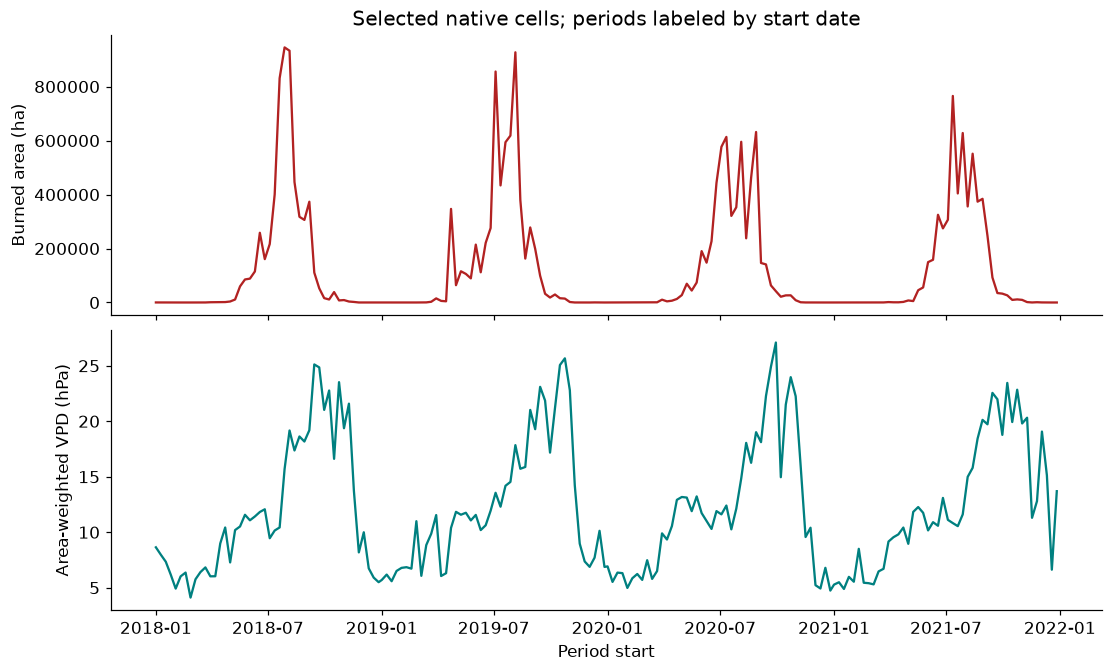

Shape: (184, 16, 16) | sum of selected cell areas: 191799.0 km²


In [3]:
out=widgets.Output()
compare=widgets.Button(description='Plot selected series',layout=widgets.Layout(width='200px'))
def plot_selection():
    f=left.get_current_cube_selection()
    v=right.get_current_cube_selection()
    if not f.size:
        print('Choose a nonempty selection.');return
    np.testing.assert_array_equal(f.time.values,v.time.values)
    # Coordinates index the original area array, preserving the exact selected support.
    import xarray as xr
    area=xr.DataArray(d['area'],dims=['latitude','longitude'],coords={'latitude':d['lat'],'longitude':d['lon']})
    area=area.sel(latitude=f.latitude,longitude=f.longitude)
    fire_total=f.sum(('latitude','longitude'),skipna=False)
    vpd_mean=v.weighted(area).mean(('latitude','longitude'))
    fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True,layout='constrained')
    axes[0].plot(f.time.values,fire_total.values,color='firebrick')
    axes[1].plot(v.time.values,vpd_mean.values,color='teal')
    axes[0].set(ylabel='Burned area (ha)',title='Selected native cells; periods labeled by start date')
    axes[1].set(ylabel='Area-weighted VPD (hPa)',xlabel='Period start')
    plt.show()
    print('Shape:',f.shape,'| sum of selected cell areas:',round(float(area.sum()/1e6),1),'km²')
def compare_selection(_=None):
    with out:
        out.clear_output(wait=True)
        plot_selection()
compare.on_click(compare_selection)
display(compare,out)
plot_selection()

## 3. Save the selection as an evidence record

The record below captures the initial selection during Run All. After exploring, rerun this cell to
capture your own bounds. A record stores a reproducible selection, not an explanation of its cause.
Retain data and software citations when exporting screenshots or using these lessons in class.

In [4]:
selection=left.get_current_cube_selection()
record={'dataset':d['provenance']['doi'],'version':'0.4','region':d['region']['id'],
        'variables':['gwis_ba','vpd'],'software':'LexCube 2.0.1',
        'xlim':list(left.xlim),'ylim':list(left.ylim),'zlim':list(left.zlim),
        'bounds_convention':'start inclusive, stop exclusive',
        'period_starts':[str(t)[:10] for t in selection.time.values],
        'data_license':'CC-BY-4.0','software_license':'GPL-3.0-or-later',
        'interpretation':'Descriptive historical comparison; not a causal or impact estimate'}
Path('seasfire-selection.json').write_text(json.dumps(record,indent=2),encoding='utf-8')
print(json.dumps(record,indent=2))

{
  "dataset": "https://doi.org/10.5281/zenodo.13834057",
  "version": "0.4",
  "region": "zambia",
  "variables": [
    "gwis_ba",
    "vpd"
  ],
  "software": "LexCube 2.0.1",
  "xlim": [
    0,
    16
  ],
  "ylim": [
    0,
    16
  ],
  "zlim": [
    0,
    184
  ],
  "bounds_convention": "start inclusive, stop exclusive",
  "period_starts": [
    "2018-01-01",
    "2018-01-09",
    "2018-01-17",
    "2018-01-25",
    "2018-02-02",
    "2018-02-10",
    "2018-02-18",
    "2018-02-26",
    "2018-03-06",
    "2018-03-14",
    "2018-03-22",
    "2018-03-30",
    "2018-04-07",
    "2018-04-15",
    "2018-04-23",
    "2018-05-01",
    "2018-05-09",
    "2018-05-17",
    "2018-05-25",
    "2018-06-02",
    "2018-06-10",
    "2018-06-18",
    "2018-06-26",
    "2018-07-04",
    "2018-07-12",
    "2018-07-20",
    "2018-07-28",
    "2018-08-05",
    "2018-08-13",
    "2018-08-21",
    "2018-08-29",
    "2018-09-06",
    "2018-09-14",
    "2018-09-22",
    "2018-09-30",
    "2018-10-08",
 

## 4. Design the next investigation

Use lesson 28 to quantify lagged associations after removing a training-period seasonal cycle.
Propose one additional source for a question about smoke, catchment water quality, or agricultural impacts.
Explain its resolution, observation timing, independent validation and licensing. Do not overlay the tiny
FTW or Tessera windows as though they cover this same location or observation period.

For a teaching demonstration of LexCube controls, consult the
[creator's illustrated documentation and animations](https://github.com/msoechting/lexcube#readme).
The text equivalent is: rotate to inspect faces; clip dimensions with start/stop bounds; inspect values
with the time-series interaction; return to exact array statistics to support a claim.

## Try it yourself

Make one comparison for each region. Retain the units and exact support, and propose a falsifiable explanation plus the independent evidence needed to test it.

## Check your reasoning

Linked views coordinate a question. They do not supply a causal design, observed impacts, operational warning skill or climate-change attribution.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [SeasFire Cube v0.4, Alonso et al. (2024)](https://doi.org/10.5281/zenodo.13834057), CC-BY-4.0. Spatial subsets and browser repackaging by this course; no spatial resampling.
- [Karasante, Alonso, Prapas, Ahuja, Carvalhais & Papoutsis (2025), SeasFire cube — a multivariate dataset for global wildfire modeling](https://doi.org/10.1038/s41597-025-04546-3), Scientific Data 12, 368.
- [ESA Open Science Catalog / EarthCODE](https://opensciencedata.esa.int/products/seasfire-cube/item), public SeasFire v0.4 mirror. Inputs used: GWIS burned area, ECMWF/Copernicus ERA5, NASA MODIS MOD13C1 v6 NDVI, and SeasFire derived VPD/cell area.
- [Exact source objects, SHA256 checksums, extraction windows and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/seasfire-provenance.json).
- [Söchting, Scheuermann, Montero & Mahecha (2025), Interactive Earth system data cube visualization in Jupyter notebooks](https://doi.org/10.1080/20964471.2025.2471646), Big Earth Data, 1–15. [LexCube 2.0.1](https://github.com/msoechting/lexcube), Maximilian Söchting and contributors, GPL-3.0-or-later.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [5]:
print('LESSON COMPLETE: 30_seasfire_lexcube_compare')

LESSON COMPLETE: 30_seasfire_lexcube_compare
